# 04 — Comparison of the eight models (Table 3, Figure 1)

Post-hoc analysis on the cached test logits (CPU only). For every test image we compute the Dice of each model, then compare pairs of models on the same 614 images.
The family has 11 pre-specified comparisons: each attention module against the Vanilla model with the same loss (6), Boundary against Dice-BCE with the same architecture (4), and the best model against the best Vanilla model (1).
CSV outputs are written to `results/`.

Inputs: the logits from the release (or notebook 01, Section 8B) and the ground-truth masks `test_masks.npy`, built from TN3K by notebook 01, Section 8A (CPU).
Figure 1 (qualitative comparison of the four architectures) needs the TN3K test images and is saved in `figures/`.

# 0. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import os
from pathlib import Path
from scipy.special import expit
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


# Paths: repository root (works from the repo root or from notebooks/), cached logits, outputs
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", REPO_ROOT))
CACHE = Path(os.environ.get("THYROID_CACHE", PROJECT_ROOT / "cache" / "logits"))
RESULTS_DIR = REPO_ROOT / "results"
FIG_DIR = REPO_ROOT / "figures"
TN3K_IMG = PROJECT_ROOT / "data" / "Thyroid Dataset" / "tn3k" / "test-image"   # only for Figure 1
RESULTS_DIR.mkdir(exist_ok=True)

masks = np.load(CACHE / "test_masks.npy").astype(bool)          # (614, 256, 256)
names = (CACHE / "test_names.txt").read_text().splitlines()

# 1. Per-image Dice

In [2]:
def dice_per_image(preds, masks):
    """Dice coefficient of every image. preds, masks: boolean (N, H, W)."""
    inter = (preds & masks).sum(axis = (1,2))                                  # pixels predicted AND in the ground truth, one value per image
    total = preds.sum(axis = (1,2)) + masks.sum(axis = (1,2))                  # predicted pixels + ground-truth pixels, one value per image
    return 2*inter / total

In [3]:
model_names = [f"{att}_{loss}" for att in ["Vanilla", "GCA", "SE", "CBAM"] for loss in ["DiceBCE", "Boundary"]]

dice_df = pd.DataFrame({
    m: dice_per_image(expit(np.load(CACHE / f"test_{m}.npy")) > 0.5, masks)
    for m in model_names
})
print(dice_df.shape)       # expected (614, 8)
print(dice_df.mean())      # per-image mean Dice of each model

(614, 8)
Vanilla_DiceBCE     0.834283
Vanilla_Boundary    0.847244
GCA_DiceBCE         0.846634
GCA_Boundary        0.844758
SE_DiceBCE          0.844194
SE_Boundary         0.835790
CBAM_DiceBCE        0.848438
CBAM_Boundary       0.844963
dtype: float64


# 2. Comparisons

In [4]:
comparisons = []
for loss in ["DiceBCE", "Boundary"]:
    for att in ["GCA", "SE", "CBAM"]:
        comparisons.append((f"{att}_{loss}", f"Vanilla_{loss}"))       # attention vs baseline, same loss
for att in ["Vanilla", "GCA", "SE", "CBAM"]:
    comparisons.append((f"{att}_Boundary", f"{att}_DiceBCE"))          # Boundary vs Dice-BCE, same attention
comparisons.append(("CBAM_DiceBCE", "Vanilla_Boundary"))               # best model vs best Vanilla model
print(len(comparisons))                                                 # expected 11

11


# 3. Paired tests on the mean difference

Table 3 reports the **mean** difference of per-image Dice with a bootstrap CI of the mean, so the test refers to the mean too.

- main test: centred bootstrap, $H_0: E[D] = 0$; resamples of $D - \bar d$ (same resamples as the CI, 10000 resamples, seed 0), two-sided p-value $(1 + \#\{|\bar d^* - \bar d| \ge |\bar d|\}) / (B + 1)$;
- checks: paired t-test (CLT, n = 614) and Wilcoxon signed-rank test. The Wilcoxon test refers to the pseudo-median (Hodges-Lehmann), which differs from the mean when the differences are skewed;
- Holm correction on the family of 11 comparisons, separately for each test;
- diagnostics: median, Hodges-Lehmann estimate and skewness of the differences.

In [5]:
from scipy.stats import ttest_1samp, skew

def mean_test(diff, n_boot=10000, seed=0):
    """Centred bootstrap test of H0: E[D] = 0 and 95% percentile CI of the mean (same resamples)."""
    rng = np.random.default_rng(seed)
    n = len(diff)
    boot = np.empty(n_boot)
    for k in range(n_boot):
        idx = rng.integers(0, n, size=n)               # n image indices sampled WITH replacement
        boot[k] = diff[idx].mean()
    obs = diff.mean()
    p = (1 + np.sum(np.abs(boot - obs) >= np.abs(obs))) / (n_boot + 1)   # null imposed by centring; smallest p = 1/(B+1)
    return obs, np.percentile(boot, [2.5, 97.5]), p

def hodges_lehmann(diff):
    """Median of the Walsh averages (D_i + D_j)/2, i <= j: the location targeted by the Wilcoxon test."""
    i, j = np.triu_indices(len(diff))
    return np.median((diff[i] + diff[j]) / 2)

rows = []
for a, b in comparisons:
    d = (dice_df[a] - dice_df[b]).values               # per-image difference, a minus b
    m, ci, p_boot = mean_test(d)
    rows.append({"a": a, "b": b, "mean_diff": m, "ci_low": ci[0], "ci_high": ci[1],
                 "median_diff": np.median(d), "hl": hodges_lehmann(d), "skew": skew(d),
                 "p_boot": p_boot, "p_t": ttest_1samp(d, 0).pvalue, "p_wilcoxon": wilcoxon(d).pvalue})

tests_mean = pd.DataFrame(rows)
for col in ["p_boot", "p_t", "p_wilcoxon"]:
    tests_mean[col + "_holm"] = multipletests(tests_mean[col], alpha=0.05, method="holm")[1]
tests_mean["significant"] = tests_mean["p_boot_holm"] < 0.05

pd.set_option("display.width", 200)
print(tests_mean[["a", "b", "mean_diff", "ci_low", "ci_high", "p_boot_holm", "p_t_holm", "p_wilcoxon_holm", "significant"]].round(4))
print()
print(tests_mean[["a", "b", "mean_diff", "median_diff", "hl", "skew"]].round(4))
dice_df.to_csv(RESULTS_DIR / "dice_per_image.csv", index=False)
tests_mean.to_csv(RESULTS_DIR / "paired_tests_mean.csv", index=False)

                   a                 b  mean_diff  ci_low  ci_high  p_boot_holm  p_t_holm  p_wilcoxon_holm  significant
0        GCA_DiceBCE   Vanilla_DiceBCE     0.0124  0.0054   0.0193       0.0020    0.0050           0.0002         True
1         SE_DiceBCE   Vanilla_DiceBCE     0.0099  0.0024   0.0176       0.0735    0.0733           0.1013        False
2       CBAM_DiceBCE   Vanilla_DiceBCE     0.0142  0.0073   0.0211       0.0011    0.0008           0.0000         True
3       GCA_Boundary  Vanilla_Boundary    -0.0025 -0.0093   0.0040       1.0000    1.0000           0.2612        False
4        SE_Boundary  Vanilla_Boundary    -0.0115 -0.0199  -0.0030       0.0672    0.0588           0.0000        False
5      CBAM_Boundary  Vanilla_Boundary    -0.0023 -0.0095   0.0045       1.0000    1.0000           0.0838        False
6   Vanilla_Boundary   Vanilla_DiceBCE     0.0130  0.0055   0.0207       0.0081    0.0091           0.0000         True
7       GCA_Boundary       GCA_DiceBCE  

# 4. Figure 1: qualitative comparison

An easy and a hard test case for the four architectures: image, ground truth, prediction (logit > 0, i.e. probability > 0.5).
The figure in the paper uses None and GCA trained with the Boundary loss, CBAM and SE trained with Dice-BCE.

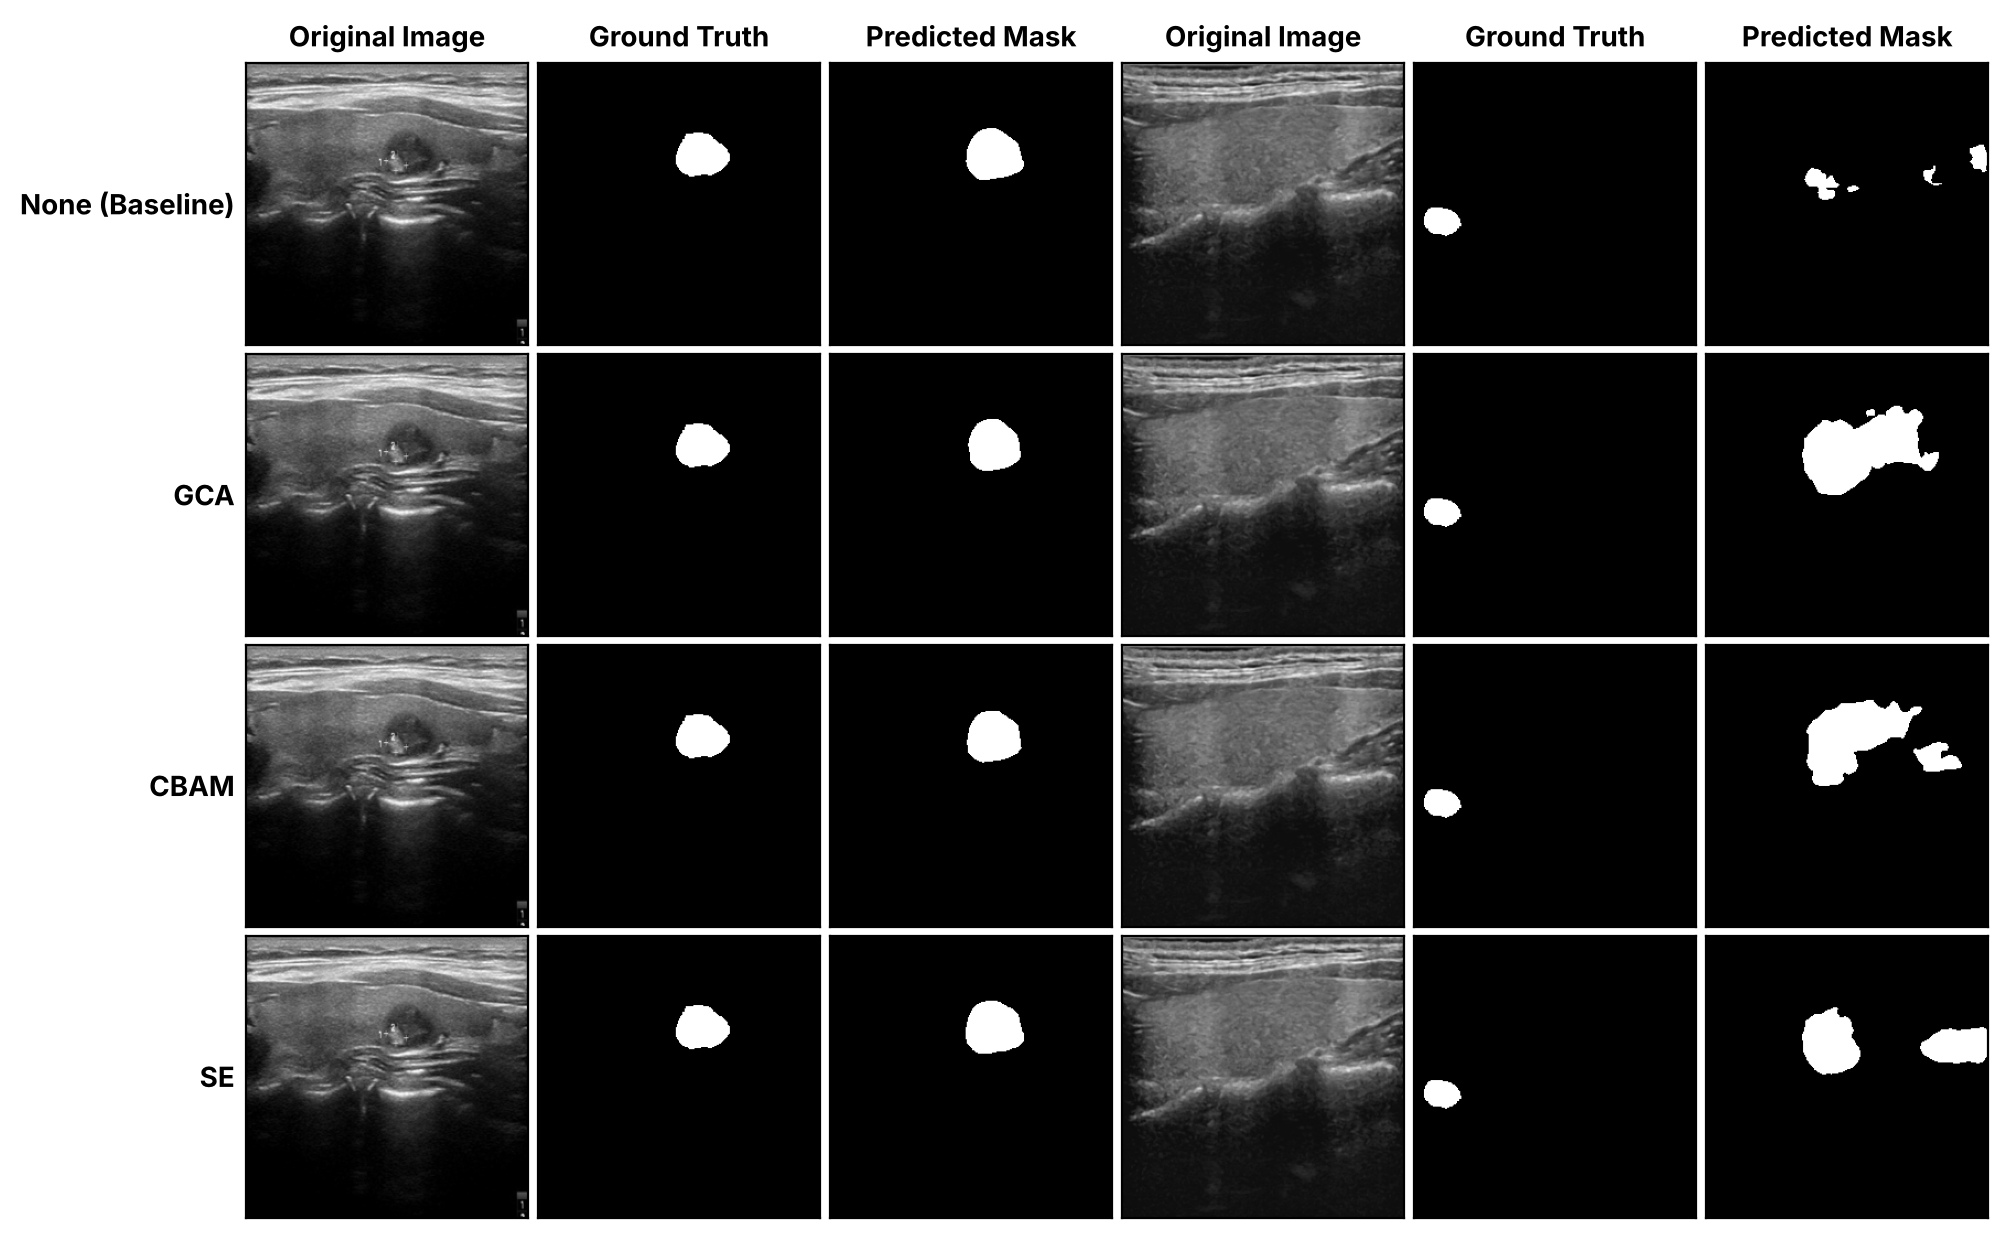

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

CASES = ["0275.jpg", "0586.jpg"]                         # easy, hard
ROWS = [("Vanilla_Boundary", "None (Baseline)"), ("GCA_Boundary", "GCA"), ("CBAM_DiceBCE", "CBAM"), ("SE_DiceBCE", "SE")]
idx = [names.index(c) for c in CASES]


def load_img(i):
    img = Image.open(TN3K_IMG / names[i]).convert("RGB")
    return np.asarray(img.resize((256, 256), Image.BILINEAR))


fig, axes = plt.subplots(len(ROWS), 3 * len(idx), figsize=(3 * 3 * len(idx) / 1.6, 3 * len(ROWS) / 1.6))
for r, (tag, label_txt) in enumerate(ROWS):
    logits = np.load(CACHE / f"test_{tag}.npy", mmap_mode="r")     # read only the two images
    for k, i in enumerate(idx):
        panels = [load_img(i), masks[i], logits[i] > 0]
        for j, panel in enumerate(panels):
            ax = axes[r, 3 * k + j]
            ax.imshow(panel, cmap=None if j == 0 else "gray")
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(["Original Image", "Ground Truth", "Predicted Mask"][j], fontsize=10, fontweight="bold")
    axes[r, 0].set_ylabel(label_txt, rotation=0, ha="right", va="center", fontsize=10, fontweight="bold")
plt.subplots_adjust(wspace=0.03, hspace=0.03)
FIG_DIR.mkdir(exist_ok=True)
plt.savefig(FIG_DIR / "fig_qualitative_comparison.png", dpi=200, bbox_inches="tight")
plt.savefig(FIG_DIR / "fig_qualitative_comparison.pdf", bbox_inches="tight")
plt.show()